### Imports & settings

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Clean publication style
plt.style.use("default")

plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.15,
        "grid.linestyle": "-",
        "axes.titleweight": "medium",
        "axes.labelweight": "regular",
        "figure.dpi": 120,
    }
)

PRIMARY = "#1f3b73"
ACCENT = "#e36414"
TEAL = "#1b998b"


# --- Helper functions ---
def make_unique_labels(names, separator=":"):
    """Return shortest unique suffix label per name.

    Example:
    - NFCORE:...:BBMAP_BBSPLIT -> BBMAP_BBSPLIT
    - If duplicate suffix exists, expand only those duplicates to
      FASTQ_QC_TRIM_FILTER_SETSTRANDEDNESS:BBMAP_BBSPLIT, etc.
    """
    input_is_index = isinstance(names, pd.Index)
    names_series = pd.Series(names, dtype="string")

    parts = names_series.str.split(separator)
    max_depth = int(parts.str.len().max())

    labels = parts.str[-1].copy()

    for depth in range(2, max_depth + 1):
        dup_mask = labels.duplicated(keep=False)
        if not dup_mask.any():
            break

        labels.loc[dup_mask] = parts.loc[dup_mask].apply(
            lambda x: (
                separator.join(x[-depth:]) if len(x) >= depth else separator.join(x)
            )
        )

    if input_is_index:
        return pd.Index(labels)
    return labels


def truncate_left(text, max_len=45, prefix="..."):
    """Left-truncate text so the end of the label remains visible."""
    text = str(text)
    if len(text) <= max_len:
        return text
    keep = max_len - len(prefix)
    return prefix + text[-keep:]


def make_unique_display_labels(names, separator=":", max_len=45, prefix="..."):
    """Create shortest unique suffix labels, then left-truncate for display."""
    unique = make_unique_labels(names, separator=separator)
    input_is_index = isinstance(unique, pd.Index)
    unique_series = pd.Series(unique, dtype="string")
    display = unique_series.apply(
        lambda s: truncate_left(s, max_len=max_len, prefix=prefix)
    )

    if input_is_index:
        return pd.Index(display)
    return display


def load_and_preprocess_trace(trace_path, verbose=True):
    """
    Load and preprocess a trace file using standardized logic.
    Returns a cleaned dataframe with only COMPLETED/CACHED tasks and valid numeric values.

    Parameters:
    -----------
    trace_path : Path or str
        Path to the trace file (tab-separated)
    verbose : bool, optional
        If True, print information about excluded tasks (default: True)

    Returns:
    --------
    pd.DataFrame
        Preprocessed dataframe with COMPLETED/CACHED tasks and cleaned numeric columns
    """
    from pathlib import Path

    trace_path = Path(trace_path)

    # Load tab-separated trace file
    df = pd.read_csv(trace_path, sep="\t", engine="python")
    df.columns = [str(c).strip() for c in df.columns]  # Clean column names

    initial_count = len(df)

    # --- Keep only COMPLETED/CACHED tasks (status-based inclusion) ---
    excluded_by_status = pd.DataFrame()
    if "status" in df.columns:
        status_norm = df["status"].astype(str).str.strip().str.upper()
        completed_mask = status_norm.isin(["COMPLETED", "CACHED"])
        excluded_by_status = df[~completed_mask].copy()
        df = df[completed_mask].copy()

    # --- Clean: replace "-" with NaN, then convert to numeric ---
    numeric_cols = [
        "%cpu",
        "cpus",
        "peak_rss",
        "memory",
        "realtime",
        "read_bytes",
        "write_bytes",
        "rchar",
        "wchar",
        "start",
        "complete",
        "duration",
    ]

    for col in numeric_cols:
        if col in df.columns:
            # Replace "-" and whitespace with NaN, then convert
            df[col] = (
                df[col]
                .astype(str)
                .str.replace("%", "", regex=False)
                .str.replace(",", "", regex=False)
                .str.replace("-", "nan", regex=False)
                .str.strip()
            )
            df[col] = pd.to_numeric(df[col], errors="coerce")

    # Track excluded tasks due to NaN/invalid critical metrics
    excluded_mask = df[["%cpu", "cpus", "peak_rss", "memory", "realtime"]].isna().any(
        axis=1
    ) | (df["cpus"] <= 0)
    excluded_numeric = df[excluded_mask].copy()

    # Drop rows with missing/invalid critical values
    df = df[~excluded_mask].copy()

    # Combined excluded set for total reporting
    excluded_tasks = pd.concat([excluded_by_status, excluded_numeric], axis=0)

    if verbose:
        print(f"Total tasks in trace: {initial_count}")
        print(f"Loaded {len(df)} tasks for analysis")

        if len(excluded_by_status) > 0:
            print(f"⚠️ Excluded non-COMPLETED/CACHED tasks: {len(excluded_by_status)}")
            cols = [c for c in ["name", "status"] if c in excluded_by_status.columns]
            if cols:
                print(excluded_by_status[cols].value_counts().to_string())
            print()

        if len(excluded_numeric) > 0:
            print(
                f"⚠️ Excluded COMPLETED/CACHED tasks with missing/invalid numeric metrics: {len(excluded_numeric)}"
            )
            cols = [c for c in ["name", "status"] if c in excluded_numeric.columns]
            if cols:
                print(excluded_numeric[cols].value_counts().to_string())
            print()

        print(f"Excluded total: {len(excluded_tasks)}")

    return df

### Load trace

In [2]:
from pathlib import Path

# 👇 Set this to your trace file location
TRACE_PATH = Path(
    "../data/rnaseq_runs/rnaseq_test_full_trace_2026-03-19_16-51-08.txt"
)  # <-- change me

# Use the standardized loading function (verbose=True by default)
df = load_and_preprocess_trace(TRACE_PATH)

Total tasks in trace: 303
Loaded 303 tasks for analysis
Excluded total: 0


### Print trace for specific tasks

In [3]:
print("\nSample of loaded tasks:")
row_idx = 15  # change this

with pd.option_context(
    "display.max_columns",
    None,
    "display.max_colwidth",
    None,
    "display.width",
    None,
):
    display(df.loc[[row_idx]])  # keeps it as a 1-row DataFrame


Sample of loaded tasks:


,task_id,hash,native_id,name,status,exit,duration,realtime,%cpu,peak_rss,peak_vmem,rchar,wchar,cpus,%mem,memory,syscr,syscw,read_bytes,write_bytes,process,cpu_model,time,disk,attempt
15,26,f7/8824ff,16524511,NFCORE_RNASEQ:RNASEQ:FASTQ_QC_TRIM_FILTER_SETSTRANDEDNESS:FASTQ_FASTQC_UMITOOLS_TRIMGALORE:FASTQC (MCF7_REP1),COMPLETED,0,546125,541000,190.0,1449156608,16479342592,18400534164,4056381,2,0.3,12884901888,35924774,14066,18459402240,6144000,NFCORE_RNASEQ:RNASEQ:FASTQ_QC_TRIM_FILTER_SETSTRANDEDNESS:FASTQ_FASTQC_UMITOOLS_TRIMGALORE:FASTQC,AMD EPYC 7343 16-Core Processor,14400000,-,1


In [11]:
def show_tasks_for_process(df: pd.DataFrame, process_label: str) -> pd.DataFrame:
    """Display all task rows for a process using make_unique_labels, with suffix fallback."""
    if "process" not in df.columns:
        raise ValueError("Column 'process' not found in DataFrame")

    target_label = str(process_label).strip()

    # Build label mapping on UNIQUE process values
    unique_processes = pd.Index(df["process"].astype(str).str.strip().dropna().unique())
    unique_labels = make_unique_labels(unique_processes)

    lookup = pd.DataFrame(
        {
            "process": unique_processes,
            "process_label": pd.Series(unique_labels, dtype="string"),
        }
    )
    lookup["process_suffix"] = lookup["process"].str.rsplit(":", n=1).str[-1]
    lookup["label_suffix"] = lookup["process_label"].str.rsplit(":", n=1).str[-1]

    # Matching strategy:
    # 1) exact unique label
    # 2) exact raw full process name
    # 3) suffix match on unique label (e.g., STAR_ALIGN)
    # 4) suffix match on raw process name
    match_exact_label = lookup["process_label"].eq(target_label)
    match_exact_process = lookup["process"].eq(target_label)
    match_label_suffix = lookup["label_suffix"].eq(target_label)
    match_process_suffix = lookup["process_suffix"].eq(target_label)

    matched_rows = lookup[
        match_exact_label
        | match_exact_process
        | match_label_suffix
        | match_process_suffix
    ].copy()

    if matched_rows.empty:
        print(f"No process found for label: {process_label}")
        suggestions = lookup.loc[
            lookup["process_label"].str.contains(target_label, case=False, na=False)
            | lookup["process_suffix"].str.contains(target_label, case=False, na=False),
            ["process_label", "process"],
        ].head(10)

        if not suggestions.empty:
            print("\nDid you mean one of these?")
            with pd.option_context(
                "display.max_rows", None, "display.max_colwidth", None
            ):
                display(suggestions)

        return df.iloc[0:0].copy()

    matched_processes = matched_rows["process"].unique()
    matches = df.loc[
        df["process"].astype(str).str.strip().isin(matched_processes)
    ].copy()

    print(
        f"Found {len(matches)} task(s) for input '{process_label}' across {len(matched_processes)} process value(s)."
    )

    with pd.option_context(
        "display.max_rows",
        None,
        "display.max_columns",
        None,
        "display.max_colwidth",
        None,
        "display.width",
        None,
    ):
        display(matches)

    return matches


# Example
star_tasks = show_tasks_for_process(df, "STAR_ALIGN")

No process found for label: STAR_ALIGN

Did you mean one of these?


,process_label,process
11,STAR_ALIGN_IGENOMES,NFCORE_RNASEQ:RNASEQ:ALIGN_STAR:STAR_ALIGN_IGENOMES


### Nextflow Process Optimization - Interactive Bubble Chart
Creates an interactive visualization to identify which processes are worth optimizing

#### Metric definitions

- **Unit conversions**  
  - `runtime_hours = realtime / 3_600_000`  
  - `mem_requested_gb = memory / 1024^3`, `mem_used_gb = peak_rss / 1024^3`  
  - `cpu_used_cores = %cpu / 100`

- **Per-process averages**  
  - `n_tasks = count(tasks)`  
  - `avg_cpus_requested = mean(cpus)`  
  - `avg_cpus_used = mean(cpu_used_cores)`  
  - `avg_cpu_efficiency = mean((cpu_used_cores / cpus) * 100)`  
  - `avg_mem_requested_gb = mean(mem_requested_gb)`  
  - `avg_mem_used_gb = mean(mem_used_gb)`  
  - `avg_mem_efficiency = mean((mem_used_gb / mem_requested_gb) * 100)`

- **Waste metrics**  
  - `cpu_waste_cores = max(cpus - cpu_used_cores, 0)`  
  - `mem_waste_gb = max(mem_requested_gb - mem_used_gb, 0)`  
  - `total_cpu_hours_wasted = Σ(cpu_waste_cores * runtime_hours)`  
  - `total_mem_gb_hours_wasted = Σ(mem_waste_gb * runtime_hours)`

- **Bubble chart mapping**  
  - **X-axis:** `total_cpu_hours_wasted`  
  - **Y-axis:** `total_mem_gb_hours_wasted`  
  - **Bubble size:** `computational_burden = total_runtime_hours * n_tasks`  
  - **Color:** `overall_efficiency = (avg_cpu_efficiency + avg_mem_efficiency) / 2`

- **Ranking score (table)**  
  - `total_waste = total_cpu_hours_wasted * 10 + total_mem_gb_hours_wasted`
  - *Note:* CPU-hours are weighted ×10 to balance with GB-hours (typical hardware ratio: ~10 GB RAM per CPU core)

In [5]:
import plotly.graph_objects as go
from IPython.display import display


def calculate_process_metrics(df: pd.DataFrame) -> pd.DataFrame:
    """Calculate aggregated optimization metrics per process from the current trace DataFrame."""
    required = ["process", "cpus", "%cpu", "memory", "peak_rss", "realtime"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    work = df.copy()

    # Ensure numeric
    for col in ["cpus", "%cpu", "memory", "peak_rss", "realtime"]:
        work[col] = pd.to_numeric(work[col], errors="coerce")

    # Keep valid rows only
    work = work.dropna(
        subset=["process", "cpus", "%cpu", "memory", "peak_rss", "realtime"]
    )
    work = work[
        (work["cpus"] > 0) & (work["memory"] > 0) & (work["realtime"] > 0)
    ].copy()

    if work.empty:
        return pd.DataFrame()

    # Per-task derived metrics
    work["runtime_hours"] = work["realtime"] / 3_600_000.0
    work["cpu_used_cores"] = work["%cpu"] / 100.0
    work["cpu_efficiency"] = (work["cpu_used_cores"] / work["cpus"]) * 100.0

    work["mem_requested_gb"] = work["memory"] / (1024**3)
    work["mem_used_gb"] = work["peak_rss"] / (1024**3)
    work["mem_efficiency"] = (work["mem_used_gb"] / work["mem_requested_gb"]) * 100.0

    # Waste (clip to avoid negative waste when usage exceeds request)
    work["cpu_waste_cores"] = (work["cpus"] - work["cpu_used_cores"]).clip(lower=0)
    work["mem_waste_gb"] = (work["mem_requested_gb"] - work["mem_used_gb"]).clip(
        lower=0
    )

    work["cpu_hours_wasted"] = work["cpu_waste_cores"] * work["runtime_hours"]
    work["mem_gb_hours_wasted"] = work["mem_waste_gb"] * work["runtime_hours"]

    metrics = (
        work.groupby("process")
        .agg(
            n_tasks=("process", "size"),
            avg_cpus_requested=("cpus", "mean"),
            avg_cpus_used=("cpu_used_cores", "mean"),
            avg_cpu_efficiency=("cpu_efficiency", "mean"),
            avg_mem_requested_gb=("mem_requested_gb", "mean"),
            avg_mem_used_gb=("mem_used_gb", "mean"),
            avg_mem_efficiency=("mem_efficiency", "mean"),
            avg_runtime_hours=("runtime_hours", "mean"),
            total_runtime_hours=("runtime_hours", "sum"),
            total_cpu_hours_wasted=("cpu_hours_wasted", "sum"),
            total_mem_gb_hours_wasted=("mem_gb_hours_wasted", "sum"),
        )
        .reset_index()
    )

    # Bubble size metric (same idea as your example)
    metrics["computational_burden"] = (
        metrics["total_runtime_hours"] * metrics["n_tasks"]
    )

    # Overall efficiency
    metrics["overall_efficiency"] = (
        metrics["avg_cpu_efficiency"] + metrics["avg_mem_efficiency"]
    ) / 2.0

    # Combined waste ranking score
    metrics["total_waste"] = (
        metrics["total_cpu_hours_wasted"] * 10.0 + metrics["total_mem_gb_hours_wasted"]
    )

    # Reuse your existing process display helper
    metrics["process_display"] = make_unique_display_labels(
        metrics["process"], max_len=40
    )

    return metrics.sort_values("total_waste", ascending=False).reset_index(drop=True)


def create_optimization_bubble_chart(
    trace_df: pd.DataFrame,
    title: str = "🎯 Nextflow Process Optimization Opportunities",
    width: int = 1200,
    height: int = 700,
    show_process_labels: bool = False,
    min_bubble_size: int = 10,
    max_bubble_size: int = 70,
) -> go.Figure:
    """Create interactive process-level optimization bubble chart."""
    metrics = calculate_process_metrics(trace_df)

    if metrics.empty:
        fig = go.Figure()
        fig.add_annotation(
            text="No process metrics available",
            xref="paper",
            yref="paper",
            x=0.5,
            y=0.5,
            showarrow=False,
            font=dict(size=18),
        )
        return fig

    # Scale bubble sizes from computational burden
    burden_values = metrics["computational_burden"].to_numpy()
    if np.nanmax(burden_values) > np.nanmin(burden_values):
        burden_norm = (burden_values - np.nanmin(burden_values)) / (
            np.nanmax(burden_values) - np.nanmin(burden_values)
        )
        bubble_sizes = min_bubble_size + (max_bubble_size - min_bubble_size) * np.sqrt(
            burden_norm
        )
    else:
        bubble_sizes = np.full(len(metrics), (min_bubble_size + max_bubble_size) / 2)

    custom_data = np.column_stack(
        [
            metrics["process"],
            metrics["n_tasks"],
            metrics["avg_runtime_hours"],
            metrics["total_runtime_hours"],
            metrics["avg_cpus_requested"],
            metrics["avg_cpus_used"],
            metrics["avg_cpu_efficiency"],
            metrics["total_cpu_hours_wasted"],
            metrics["avg_mem_requested_gb"],
            metrics["avg_mem_used_gb"],
            metrics["avg_mem_efficiency"],
            metrics["total_mem_gb_hours_wasted"],
            metrics["overall_efficiency"],
            metrics["computational_burden"],
        ]
    )

    fig = go.Figure()
    fig.add_trace(
        go.Scatter(
            x=metrics["total_cpu_hours_wasted"],
            y=metrics["total_mem_gb_hours_wasted"],
            mode="markers+text" if show_process_labels else "markers",
            text=metrics["process_display"] if show_process_labels else None,
            textposition="middle center",
            textfont=dict(size=9, color="white"),
            marker=dict(
                size=bubble_sizes,
                sizemode="diameter",
                color=metrics["overall_efficiency"].clip(lower=0, upper=100),
                colorscale="RdYlGn",
                cmin=0,
                cmax=100,
                opacity=0.85,
                line=dict(width=1.5, color="white"),
                colorbar=dict(title="Efficiency (%)", thickness=16, len=0.7, x=1.02),
            ),
            hovertext=metrics["process_display"],
            customdata=custom_data,
            hovertemplate=(
                "<b>%{hovertext}</b><br><br>"
                "Tasks: %{customdata[1]}<br>"
                "Avg Runtime: %{customdata[2]:.2f} h<br>"
                "Total Runtime: %{customdata[3]:.1f} h<br><br>"
                "CPU used/requested: %{customdata[5]:.1f} / %{customdata[4]:.1f} cores<br>"
                "CPU efficiency: %{customdata[6]:.1f}%<br>"
                "CPU-hours wasted: %{x:.2f}<br><br>"
                "Memory used/requested: %{customdata[9]:.1f} / %{customdata[8]:.1f} GB<br>"
                "Memory efficiency: %{customdata[10]:.1f}%<br>"
                "Memory GB-hours wasted: %{y:.2f}<br><br>"
                "Overall efficiency: %{customdata[12]:.1f}%<br>"
                "Computational burden: %{customdata[13]:.1f}<extra></extra>"
            ),
            name="Processes",
        )
    )

    fig.update_layout(
        title=dict(
            text=f"{title}<br><sub>Bubble size = Runtime × Tasks | Color = Overall efficiency</sub>",
            x=0.5,
            xanchor="center",
        ),
        xaxis=dict(
            title="Total CPU-hours wasted", showgrid=True, gridcolor="lightgray"
        ),
        yaxis=dict(
            title="Total Memory GB-hours wasted", showgrid=True, gridcolor="lightgray"
        ),
        plot_bgcolor="white",
        paper_bgcolor="white",
        hovermode="closest",
        width=width,
        height=height,
        showlegend=False,
    )

    fig.add_annotation(
        text="Top-right = highest optimization priority",
        xref="paper",
        yref="paper",
        x=0.99,
        y=0.98,
        showarrow=False,
        xanchor="right",
        yanchor="top",
        font=dict(size=11, color="darkred"),
        bgcolor="rgba(255,255,255,0.85)",
        bordercolor="darkred",
        borderwidth=1,
    )

    return fig


def get_top_optimization_candidates(
    trace_df: pd.DataFrame, n: int = 10
) -> pd.DataFrame:
    """Return top-N optimization candidates."""
    metrics = calculate_process_metrics(trace_df)
    if metrics.empty:
        return metrics

    cols = [
        "process_display",
        "n_tasks",
        "avg_cpus_requested",
        "avg_mem_requested_gb",
        "avg_cpu_efficiency",
        "avg_mem_efficiency",
        "overall_efficiency",
        "total_cpu_hours_wasted",
        "total_mem_gb_hours_wasted",
        "total_waste",
    ]
    top_n = metrics.head(n)[cols].copy()

    numeric_cols = top_n.select_dtypes(include=[np.number]).columns
    top_n[numeric_cols] = top_n[numeric_cols].round(2)
    return top_n


# ---- Run on current notebook df ----
fig = create_optimization_bubble_chart(df)
fig.show()

print("\n🏆 Top optimization candidates\n")
display(get_top_optimization_candidates(df, n=10))


🏆 Top optimization candidates



,process_display,n_tasks,avg_cpus_requested,avg_mem_requested_gb,avg_cpu_efficiency,avg_mem_efficiency,overall_efficiency,total_cpu_hours_wasted,total_mem_gb_hours_wasted,total_waste
0,STAR_ALIGN_IGENOMES,8,12.0,72.0,47.51,49.74,48.63,39.43,226.75,621.08
1,TRIMGALORE,8,12.0,72.0,57.70,1.74,29.72,22.20,308.83,530.81
2,PICARD_MARKDUPLICATES,8,6.0,36.0,16.79,73.39,45.09,26.41,49.10,313.19
3,QUALIMAP_RNASEQ,8,6.0,36.0,15.62,25.04,20.33,19.28,102.56,295.32
4,RSEQC_READDUPLICATION,8,6.0,36.0,15.68,45.46,30.57,12.65,46.73,173.23
5,RSEQC_READDISTRIBUTION,8,6.0,36.0,15.43,2.98,9.20,6.38,44.01,107.81
6,RSEQC_JUNCTIONSATURATION,8,6.0,36.0,15.89,3.70,9.80,6.35,43.44,106.94
7,RSEQC_BAMSTAT,8,6.0,36.0,15.04,0.14,7.59,5.84,41.23,99.58
8,RSEQC_JUNCTIONANNOTATION,8,6.0,36.0,14.37,0.41,7.39,5.62,39.18,95.36
9,STRINGTIE_STRINGTIE,8,6.0,36.0,19.01,3.25,11.13,4.45,31.78,76.24


### Nextflow Process Resource Intensity - Interactive Bubble Chart
Shows which processes consume the most computational resources (actual usage)

#### Resource intensity metric definitions

- **Unit conversions**  
  - `runtime_hours = realtime / 3_600_000`  
  - `cpu_used_cores = %cpu / 100` (actual cores used, not requested)  
  - `mem_used_gb = peak_rss / 1024^3` (actual memory used, not requested)

- **Per-task consumption**  
  - `cpu_core_hours = cpu_used_cores × runtime_hours` (actual CPU consumption)  
  - `mem_gb_hours = mem_used_gb × runtime_hours` (actual memory consumption)

- **Per-process aggregation**  
  - `n_tasks = count(tasks)`  
  - `total_runtime_hours = Σ(runtime_hours)`  
  - `avg_runtime_hours = mean(runtime_hours)`  
  - `total_cpu_core_hours = Σ(cpu_core_hours)` — total actual CPU consumed  
  - `total_mem_gb_hours = Σ(mem_gb_hours)` — total actual memory consumed  
  - `avg_cpu_cores_used = mean(cpu_used_cores)`  
  - `avg_mem_gb_used = mean(mem_used_gb)`

- **Bubble chart mapping**  
  - **X-axis:** `total_cpu_core_hours` (actual CPU consumption)  
  - **Y-axis:** `total_mem_gb_hours` (actual memory consumption)  
  - **Bubble size:** `n_tasks` (parallelization level)  
  - **Color:** `avg_runtime_hours` (task duration)

- **Ranking score (table)**  
  - `resource_intensity_score = total_cpu_core_hours × 10 + total_mem_gb_hours`
  - *Note:* CPU-core-hours are weighted ×10 to balance with GB-hours on a similar scale (adjust factor based on your hardware cost ratios)

In [6]:
def calculate_resource_intensity_metrics(df: pd.DataFrame) -> pd.DataFrame:
    """Calculate actual resource consumption metrics per process (used resources, not requested)."""
    required = ["process", "cpus", "%cpu", "memory", "peak_rss", "realtime"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    work = df.copy()

    # Ensure numeric
    for col in ["cpus", "%cpu", "memory", "peak_rss", "realtime"]:
        work[col] = pd.to_numeric(work[col], errors="coerce")

    # Keep valid rows only
    work = work.dropna(
        subset=["process", "cpus", "%cpu", "memory", "peak_rss", "realtime"]
    )
    work = work[
        (work["cpus"] > 0) & (work["memory"] > 0) & (work["realtime"] > 0)
    ].copy()

    if work.empty:
        return pd.DataFrame()

    # Per-task actual usage metrics
    work["runtime_hours"] = work["realtime"] / 3_600_000.0
    work["cpu_used_cores"] = work["%cpu"] / 100.0
    work["mem_used_gb"] = work["peak_rss"] / (1024**3)

    # Resource-time products (actual consumption)
    work["cpu_core_hours"] = work["cpu_used_cores"] * work["runtime_hours"]
    work["mem_gb_hours"] = work["mem_used_gb"] * work["runtime_hours"]

    metrics = (
        work.groupby("process")
        .agg(
            n_tasks=("process", "size"),
            avg_runtime_hours=("runtime_hours", "mean"),
            total_runtime_hours=("runtime_hours", "sum"),
            avg_cpu_cores_used=("cpu_used_cores", "mean"),
            total_cpu_core_hours=("cpu_core_hours", "sum"),
            avg_mem_gb_used=("mem_used_gb", "mean"),
            total_mem_gb_hours=("mem_gb_hours", "sum"),
        )
        .reset_index()
    )

    # Overall resource intensity score (CPU and memory weighted equally)
    # Normalized to 0-100 scale for coloring
    metrics["resource_intensity_score"] = (
        metrics["total_cpu_core_hours"] * 10.0 + metrics["total_mem_gb_hours"]
    )

    # Process display names
    metrics["process_display"] = make_unique_display_labels(
        metrics["process"], max_len=40
    )

    return metrics.sort_values("resource_intensity_score", ascending=False).reset_index(
        drop=True
    )


def create_resource_intensity_bubble_chart(
    trace_df: pd.DataFrame,
    title: str = "📊 Nextflow Process Resource Intensity",
    width: int = 1200,
    height: int = 700,
    show_process_labels: bool = False,
    min_bubble_size: int = 10,
    max_bubble_size: int = 70,
) -> go.Figure:
    """Create interactive process-level resource intensity bubble chart."""
    metrics = calculate_resource_intensity_metrics(trace_df)

    if metrics.empty:
        fig = go.Figure()
        fig.add_annotation(
            text="No process metrics available",
            xref="paper",
            yref="paper",
            x=0.5,
            y=0.5,
            showarrow=False,
            font=dict(size=18),
        )
        return fig

    # Scale bubble sizes from task count
    task_values = metrics["n_tasks"].to_numpy()
    if np.nanmax(task_values) > np.nanmin(task_values):
        task_norm = (task_values - np.nanmin(task_values)) / (
            np.nanmax(task_values) - np.nanmin(task_values)
        )
        bubble_sizes = min_bubble_size + (max_bubble_size - min_bubble_size) * np.sqrt(
            task_norm
        )
    else:
        bubble_sizes = np.full(len(metrics), (min_bubble_size + max_bubble_size) / 2)

    custom_data = np.column_stack(
        [
            metrics["process"],
            metrics["n_tasks"],
            metrics["avg_runtime_hours"],
            metrics["total_runtime_hours"],
            metrics["avg_cpu_cores_used"],
            metrics["total_cpu_core_hours"],
            metrics["avg_mem_gb_used"],
            metrics["total_mem_gb_hours"],
            metrics["resource_intensity_score"],
        ]
    )

    fig = go.Figure()
    fig.add_trace(
        go.Scatter(
            x=metrics["total_cpu_core_hours"],
            y=metrics["total_mem_gb_hours"],
            mode="markers+text" if show_process_labels else "markers",
            text=metrics["process_display"] if show_process_labels else None,
            textposition="middle center",
            textfont=dict(size=9, color="white"),
            marker=dict(
                size=bubble_sizes,
                sizemode="diameter",
                color=metrics["avg_runtime_hours"],
                colorscale="Viridis",
                opacity=0.85,
                line=dict(width=1.5, color="white"),
                colorbar=dict(title="Avg Runtime (h)", thickness=16, len=0.7, x=1.02),
            ),
            hovertext=metrics["process_display"],
            customdata=custom_data,
            hovertemplate=(
                "<b>%{hovertext}</b><br><br>"
                "Tasks: %{customdata[1]}<br>"
                "Avg Runtime: %{customdata[2]:.2f} h<br>"
                "Total Runtime: %{customdata[3]:.1f} h<br><br>"
                "Avg CPU cores used: %{customdata[4]:.1f}<br>"
                "Total CPU-core-hours: %{x:.2f}<br><br>"
                "Avg Memory used: %{customdata[6]:.1f} GB<br>"
                "Total Memory GB-hours: %{y:.2f}<br><br>"
                "Resource intensity score: %{customdata[8]:.1f}<extra></extra>"
            ),
            name="Processes",
        )
    )

    fig.update_layout(
        title=dict(
            text=f"{title}<br><sub>Bubble size = Task count | Color = Avg runtime per task</sub>",
            x=0.5,
            xanchor="center",
        ),
        xaxis=dict(
            title="Total CPU-core-hours consumed", showgrid=True, gridcolor="lightgray"
        ),
        yaxis=dict(
            title="Total Memory GB-hours consumed",
            showgrid=True,
            gridcolor="lightgray",
        ),
        plot_bgcolor="white",
        paper_bgcolor="white",
        hovermode="closest",
        width=width,
        height=height,
        showlegend=False,
    )

    fig.add_annotation(
        text="Top-right = highest resource consumption",
        xref="paper",
        yref="paper",
        x=0.99,
        y=0.98,
        showarrow=False,
        xanchor="right",
        yanchor="top",
        font=dict(size=11, color="darkblue"),
        bgcolor="rgba(255,255,255,0.85)",
        bordercolor="darkblue",
        borderwidth=1,
    )

    return fig


def get_top_resource_intensive_processes(
    trace_df: pd.DataFrame, n: int = 10
) -> pd.DataFrame:
    """Return top-N most resource-intensive processes."""
    metrics = calculate_resource_intensity_metrics(trace_df)
    if metrics.empty:
        return metrics

    cols = [
        "process_display",
        "n_tasks",
        "avg_runtime_hours",
        "total_runtime_hours",
        "avg_cpu_cores_used",
        "total_cpu_core_hours",
        "avg_mem_gb_used",
        "total_mem_gb_hours",
        "resource_intensity_score",
    ]
    top_n = metrics.head(n)[cols].copy()

    numeric_cols = top_n.select_dtypes(include=[np.number]).columns
    top_n[numeric_cols] = top_n[numeric_cols].round(2)
    return top_n


# ---- Run on current notebook df ----
fig = create_resource_intensity_bubble_chart(df)
fig.show()

print("\n🔥 Top resource-intensive processes\n")
display(get_top_resource_intensive_processes(df, n=10))


🔥 Top resource-intensive processes



,process_display,n_tasks,avg_runtime_hours,total_runtime_hours,avg_cpu_cores_used,total_cpu_core_hours,avg_mem_gb_used,total_mem_gb_hours,resource_intensity_score
0,STAR_ALIGN_IGENOMES,8,0.78,6.27,5.70,35.77,35.82,224.49,582.21
1,TRIMGALORE,8,0.55,4.36,6.92,30.17,1.25,5.39,307.11
2,PICARD_MARKDUPLICATES,8,0.66,5.28,1.01,5.29,26.42,141.12,194.05
3,QUANTIFY_PSEUDO_ALIGNMENT:SALMON_QUANT,8,0.32,2.54,5.42,13.77,17.44,44.28,181.97
4,QUALIMAP_RNASEQ,8,0.48,3.81,0.94,3.58,9.01,34.57,70.36
5,RSEQC_READDUPLICATION,8,0.31,2.50,0.94,2.34,16.37,43.24,66.69
6,SAMTOOLS_SORT_QUALIMAP,8,0.15,1.19,4.61,5.46,5.26,6.24,60.80
7,QUANTIFY_BAM_SALMON:SALMON_QUANT,8,0.10,0.82,5.06,4.12,5.68,4.65,45.86
8,SAMTOOLS_SORT,8,0.10,0.78,4.46,3.47,5.30,4.13,38.82
9,SALMON_INDEX,1,0.51,0.51,4.51,2.30,18.38,9.37,32.36


#### Combined view: Optimization vs Resource Intensity
Sortable table showing both waste/efficiency metrics and actual consumption metrics

In [12]:
def get_combined_process_analysis(trace_df: pd.DataFrame) -> pd.DataFrame:
    """
    Create a comprehensive sortable table combining optimization and resource intensity metrics.

    Returns DataFrame with columns covering:
    - Optimization perspective: efficiency, waste
    - Resource intensity perspective: actual consumption
    """
    # Get both metric sets
    opt_metrics = calculate_process_metrics(trace_df)
    intensity_metrics = calculate_resource_intensity_metrics(trace_df)

    if opt_metrics.empty or intensity_metrics.empty:
        return pd.DataFrame()

    # Merge on process (both have the same process column)
    combined = opt_metrics.merge(
        intensity_metrics, on="process", how="outer", suffixes=("", "_intensity")
    )

    # Select and rename key columns for clarity
    result = pd.DataFrame(
        {
            "Process": combined["process_display"],
            # Basic stats
            "Tasks": combined["n_tasks"],
            "Total Runtime (h)": combined["total_runtime_hours"],
            # === OPTIMIZATION METRICS ===
            "Efficiency (%)": combined["overall_efficiency"],
            "CPU Efficiency (%)": combined["avg_cpu_efficiency"],
            "Mem Efficiency (%)": combined["avg_mem_efficiency"],
            "CPU-hours Wasted": combined["total_cpu_hours_wasted"],
            "Mem GB-hours Wasted": combined["total_mem_gb_hours_wasted"],
            "Total Waste Score": combined["total_waste"],
            # === RESOURCE INTENSITY METRICS ===
            "CPU-core-hours Used": combined["total_cpu_core_hours"],
            "Mem GB-hours Used": combined["total_mem_gb_hours"],
            "Resource Intensity Score": combined["resource_intensity_score"],
            "Avg CPU Used (cores)": combined["avg_cpu_cores_used"],
            "Avg Mem Used (GB)": combined["avg_mem_gb_used"],
        }
    )

    # Round numeric columns
    numeric_cols = result.select_dtypes(include=[np.number]).columns
    result[numeric_cols] = result[numeric_cols].round(2)

    return result


# Create interactive sortable table
combined_df = get_combined_process_analysis(df)

print("📊 Combined Process Analysis - Sort by any column to explore\n")
print("💡 TIP: Click column headers in the table below to sort\n")

# Display with sorting enabled (in Jupyter, you can click column headers)
"""display(
    combined_df.style.background_gradient(
        subset=["Efficiency (%)"], cmap="RdYlGn", vmin=0, vmax=100
    ).background_gradient(
        subset=["Total Waste Score", "Resource Intensity Score"], cmap="YlOrRd"
    )
)

# Also provide instructions for manual sorting
print("\n📌 To sort programmatically, use:")
print(
    "   combined_df.sort_values('Total Waste Score', ascending=False)  # Optimization priority"
)
print(
    "   combined_df.sort_values('Resource Intensity Score', ascending=False)  # Consumption priority"
)
print(
    "   combined_df.sort_values('Efficiency (%)', ascending=True)  # Worst efficiency first"
)"""

📊 Combined Process Analysis - Sort by any column to explore

💡 TIP: Click column headers in the table below to sort



'display(\n    combined_df.style.background_gradient(\n        subset=["Efficiency (%)"], cmap="RdYlGn", vmin=0, vmax=100\n    ).background_gradient(\n        subset=["Total Waste Score", "Resource Intensity Score"], cmap="YlOrRd"\n    )\n)\n\n# Also provide instructions for manual sorting\nprint("\n📌 To sort programmatically, use:")\nprint(\n    "   combined_df.sort_values(\'Total Waste Score\', ascending=False)  # Optimization priority"\n)\nprint(\n    "   combined_df.sort_values(\'Resource Intensity Score\', ascending=False)  # Consumption priority"\n)\nprint(\n    "   combined_df.sort_values(\'Efficiency (%)\', ascending=True)  # Worst efficiency first"\n)'

In [8]:
# Example: View top processes by different criteria

print("=" * 80)
print("🎯 TOP 5 OPTIMIZATION TARGETS (highest waste)")
print("=" * 80)
display(combined_df.sort_values("Total Waste Score", ascending=False).head(5))

print("\n" + "=" * 80)
print("🔥 TOP 5 RESOURCE CONSUMERS (highest actual usage)")
print("=" * 80)
display(combined_df.sort_values("Resource Intensity Score", ascending=False).head(5))

print("\n" + "=" * 80)
print("⚠️ TOP 5 LEAST EFFICIENT (lowest efficiency)")
print("=" * 80)
display(combined_df.sort_values("Efficiency (%)", ascending=True).head(5))

🎯 TOP 5 OPTIMIZATION TARGETS (highest waste)


,Process,Tasks,Total Runtime (h),Efficiency (%),CPU Efficiency (%),Mem Efficiency (%),CPU-hours Wasted,Mem GB-hours Wasted,Total Waste Score,CPU-core-hours Used,Mem GB-hours Used,Resource Intensity Score,Avg CPU Used (cores),Avg Mem Used (GB)
9,STAR_ALIGN_IGENOMES,8,6.27,48.63,47.51,49.74,39.43,226.75,621.08,35.77,224.49,582.21,5.70,35.82
32,TRIMGALORE,8,4.36,29.72,57.70,1.74,22.20,308.83,530.81,30.17,5.39,307.11,6.92,1.25
13,PICARD_MARKDUPLICATES,8,5.28,45.09,16.79,73.39,26.41,49.10,313.19,5.29,141.12,194.05,1.01,26.42
37,QUALIMAP_RNASEQ,8,3.81,20.33,15.62,25.04,19.28,102.56,295.32,3.58,34.57,70.36,0.94,9.01
21,RSEQC_READDUPLICATION,8,2.50,30.57,15.68,45.46,12.65,46.73,173.23,2.34,43.24,66.69,0.94,16.37



🔥 TOP 5 RESOURCE CONSUMERS (highest actual usage)


,Process,Tasks,Total Runtime (h),Efficiency (%),CPU Efficiency (%),Mem Efficiency (%),CPU-hours Wasted,Mem GB-hours Wasted,Total Waste Score,CPU-core-hours Used,Mem GB-hours Used,Resource Intensity Score,Avg CPU Used (cores),Avg Mem Used (GB)
9,STAR_ALIGN_IGENOMES,8,6.27,48.63,47.51,49.74,39.43,226.75,621.08,35.77,224.49,582.21,5.70,35.82
32,TRIMGALORE,8,4.36,29.72,57.70,1.74,22.20,308.83,530.81,30.17,5.39,307.11,6.92,1.25
13,PICARD_MARKDUPLICATES,8,5.28,45.09,16.79,73.39,26.41,49.10,313.19,5.29,141.12,194.05,1.01,26.42
47,QUANTIFY_PSEUDO_ALIGNMENT:SALMON_QUANT,8,2.54,69.41,90.38,48.43,1.47,47.15,61.84,13.77,44.28,181.97,5.42,17.44
37,QUALIMAP_RNASEQ,8,3.81,20.33,15.62,25.04,19.28,102.56,295.32,3.58,34.57,70.36,0.94,9.01



⚠️ TOP 5 LEAST EFFICIENT (lowest efficiency)


,Process,Tasks,Total Runtime (h),Efficiency (%),CPU Efficiency (%),Mem Efficiency (%),CPU-hours Wasted,Mem GB-hours Wasted,Total Waste Score,CPU-core-hours Used,Mem GB-hours Used,Resource Intensity Score,Avg CPU Used (cores),Avg Mem Used (GB)
5,...:BAM_STATS_SAMTOOLS:SAMTOOLS_IDXSTATS,7,0.01,1.51,2.96,0.07,0.01,0.04,0.10,0.00,0.00,0.00,0.03,0.00
11,...:BAM_STATS_SAMTOOLS:SAMTOOLS_IDXSTATS,2,0.00,2.61,5.15,0.06,0.00,0.00,0.01,0.00,0.00,0.00,0.05,0.00
1,MAKE_TRANSCRIPTS_FASTA,1,0.01,4.33,7.12,1.54,0.14,0.87,2.23,0.01,0.01,0.12,0.85,1.11
16,RSEQC_INFEREXPERIMENT,8,0.03,5.67,11.13,0.20,0.16,1.01,2.60,0.01,0.00,0.10,0.67,0.07
46,...SUMMARIZEDEXPERIMENT:TXIMETA_TXIMPORT,1,0.01,6.03,9.32,2.75,0.05,0.35,0.89,0.01,0.01,0.07,0.56,0.99


### Top Processes by Runtime

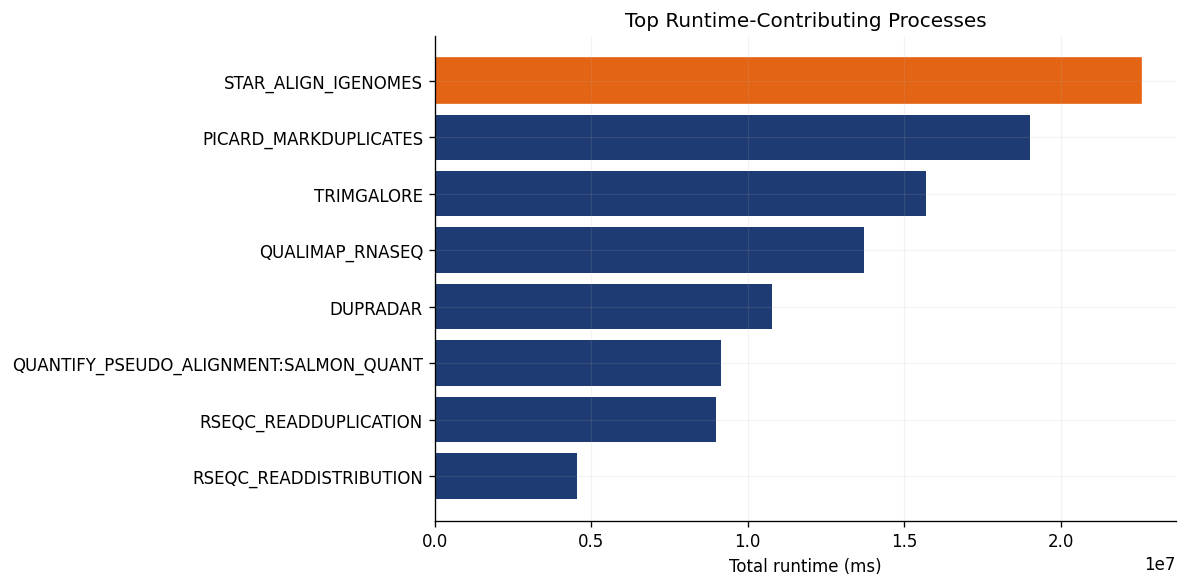

In [9]:
# Build runtime table for all processes first (for global label disambiguation)
proc_runtime_all = df.groupby("process")["realtime"].sum().sort_values(ascending=False)

# Compute display labels against ALL processes
all_processes = proc_runtime_all.index
all_display_labels = make_unique_display_labels(all_processes, max_len=45)
label_map = dict(zip(all_processes, all_display_labels))

# Then select top 8 for plotting
proc_runtime = proc_runtime_all.head(8).copy()
proc_runtime.index = proc_runtime.index.map(label_map)

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(proc_runtime.index[::-1], proc_runtime.values[::-1], color=PRIMARY)

# Highlight largest
bars[-1].set_color(ACCENT)

ax.set_xlabel("Total runtime (ms)")
ax.set_title("Top Runtime-Contributing Processes")

plt.tight_layout()
plt.show()

### Parallelism Factor

In [10]:
total_task_time = df["realtime"].sum()
pipeline_runtime = df["complete"].max() - df["start"].min()

parallelism = total_task_time / pipeline_runtime

fig, ax = plt.subplots(figsize=(5, 4))

ax.bar(
    ["Sum of task runtime", "Pipeline runtime"],
    [total_task_time, pipeline_runtime],
    color=[PRIMARY, TEAL],
)

ax.set_title(f"Parallelism Factor = {parallelism:.1f}×")
ax.set_ylabel("Time (ms)")

plt.tight_layout()
plt.show()

KeyError: 'complete'